# 31 — Cross-Species Integration Analysis

Chimera's integration is **per-gene**, not per-cell.
The primary outputs are α (integration coefficient) and Δα (discrepancy from conservation prior),
not species-invariant embeddings.

**Important framing (Caveat 34)**: The encoder receives `species_oh` as input, so latent z
retains species identity by design. Integration quality is evaluated through:
1. **Alpha-stratified expression conservation** — high-α genes should show similar expression across species
2. **Shared decoder consistency** — shared-only expression as the integration product
3. **Per-cell-type expression alignment** — within shared cell types
4. **UMAP visualization** — cell-type structure preservation

In [1]:
import sys, os, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="scvi")
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import anndata as ad
import scanpy as sc
import torch
from pathlib import Path
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

from chimera._model import ChimeraModel

plt.rcParams.update({
    "figure.dpi": 150, "font.size": 9, "axes.titlesize": 10,
    "figure.facecolor": "white",
})
REPO = Path("..").resolve()

# ---- Configuration ----
RUN_DIR = REPO / "training" / "runs" / "iter16-slow-classifier"
ADATA_PATH = REPO / "data" / "processed" / "camex_human_monkey.h5ad"

## 1. Load Model & Data

In [2]:
adata = ad.read_h5ad(ADATA_PATH)
ChimeraModel.setup_anndata(adata, species_key="species", batch_key="batch")
model = ChimeraModel.load(str(RUN_DIR / "model"), adata=adata)
model.module.to("cpu"); model.module.eval()

# Extract outputs
alpha = model.get_alpha()
delta_alpha = model.get_delta_alpha()
z = model.get_latent_representation(adata)
mu_shared = model.get_shared_only_expression(adata)
prior = model.module.conservation_prior.cpu().numpy()

species = adata.obs["species"].values
species_codes = adata.obs["species"].cat.codes.values
cell_types = adata.obs["cell_type"].values
n_sp = len(adata.obs["species"].unique())

# Gene name mapping
ot = pd.read_csv(REPO / "data" / "processed" / "ortholog_table.csv")
ortho_ids = [int(v.replace("ortho_","")) for v in adata.var_names]
gene_map = {}
for oid in ortho_ids:
    row = ot[ot["ortholog_group_id"]==oid]
    gene_map[f"ortho_{oid}"] = row.iloc[0]["hsapiens_gene_name"] if len(row) else f"ortho_{oid}"
gene_names = np.array([gene_map[v] for v in adata.var_names])

# Shared cell types
ct_counts = adata.obs.groupby(["species","cell_type"], observed=True).size().unstack(fill_value=0)
shared_cts = list(ct_counts.columns[(ct_counts > 0).all(axis=0)])
print(f"Shared cell types: {shared_cts}")
print(f"Species: {list(adata.obs['species'].unique())}")
print(f"Genes: {len(alpha)}, Cells: {adata.n_obs}")

INFO     File                                                                                                      
         /Users/kemalinecik/git_nosync/master_chimera/chimera/training/runs/iter16-slow-classifier/model/model.pt  
         already downloaded                                                                                        


Shared cell types: ['Cholangio', 'Endothelial', 'Hepatocytes', 'fibroblasts']
Species: ['Human', 'Monkey']
Genes: 8430, Cells: 12608


## 2. Pre-Integration Baseline (Raw Expression)

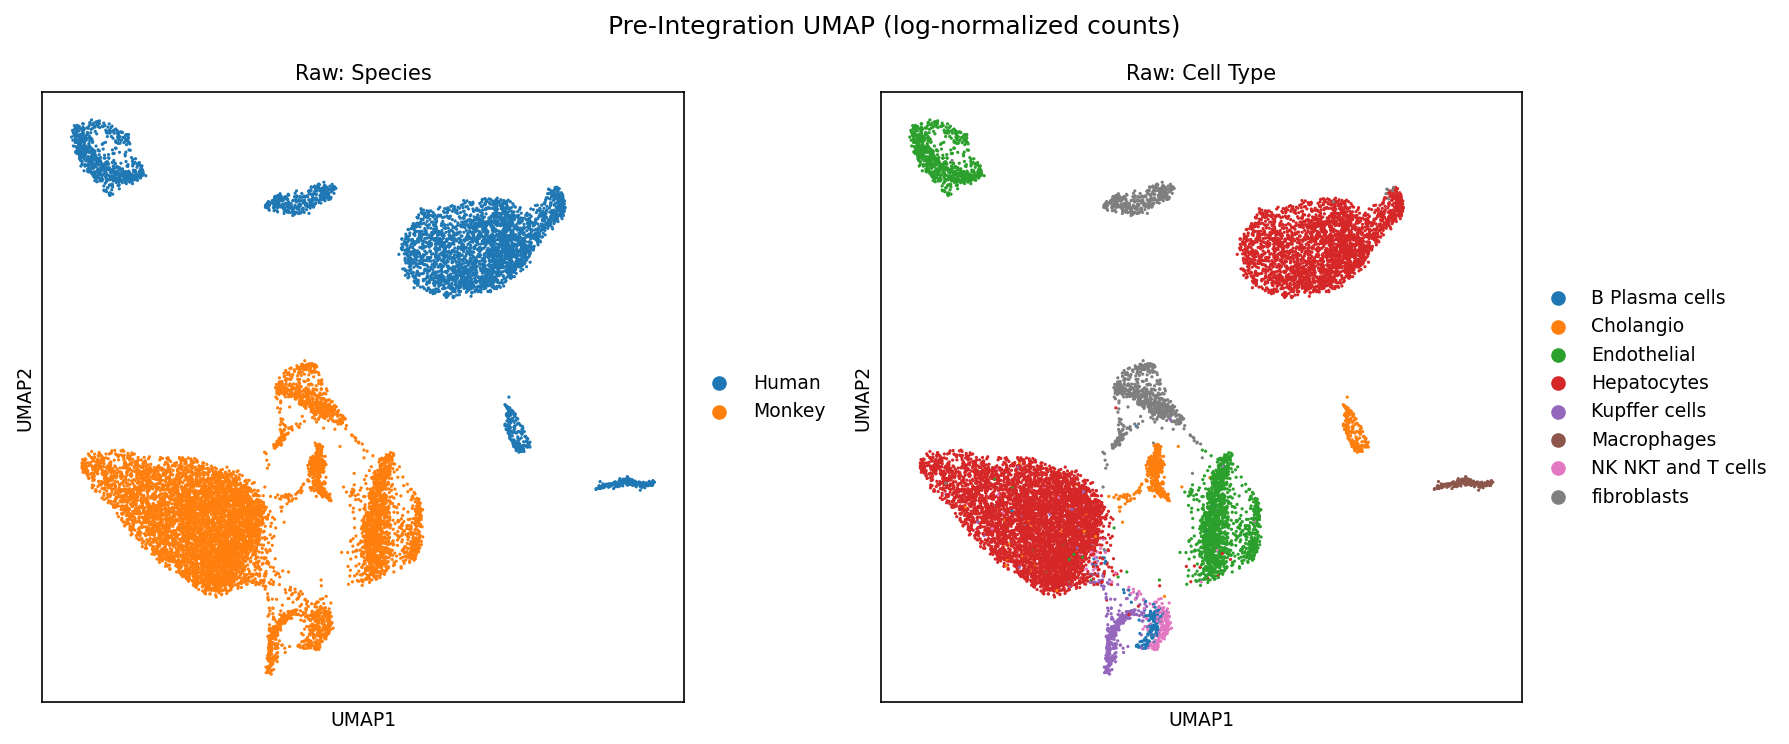

In [3]:
# Log-normalize raw counts
adata_raw = adata.copy()
sc.pp.normalize_total(adata_raw, target_sum=1e4)
sc.pp.log1p(adata_raw)
sc.pp.pca(adata_raw, n_comps=30)
sc.pp.neighbors(adata_raw, n_pcs=30)
sc.tl.umap(adata_raw, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc.pl.umap(adata_raw, color="species", ax=axes[0], show=False, title="Raw: Species")
sc.pl.umap(adata_raw, color="cell_type", ax=axes[1], show=False, title="Raw: Cell Type")
fig.suptitle("Pre-Integration UMAP (log-normalized counts)", fontsize=12)
fig.tight_layout(); plt.show()

## 3. Chimera Latent Space (z) UMAP

**Expected**: z retains species identity (Caveat 34 — encoder receives `species_oh`).
The adversarial classifier reduces LINEAR species separability but cannot eliminate the
nonlinear species signal that the encoder encodes. This is by design: z serves the
shared + residual decoder, and the primary output is α, not z.

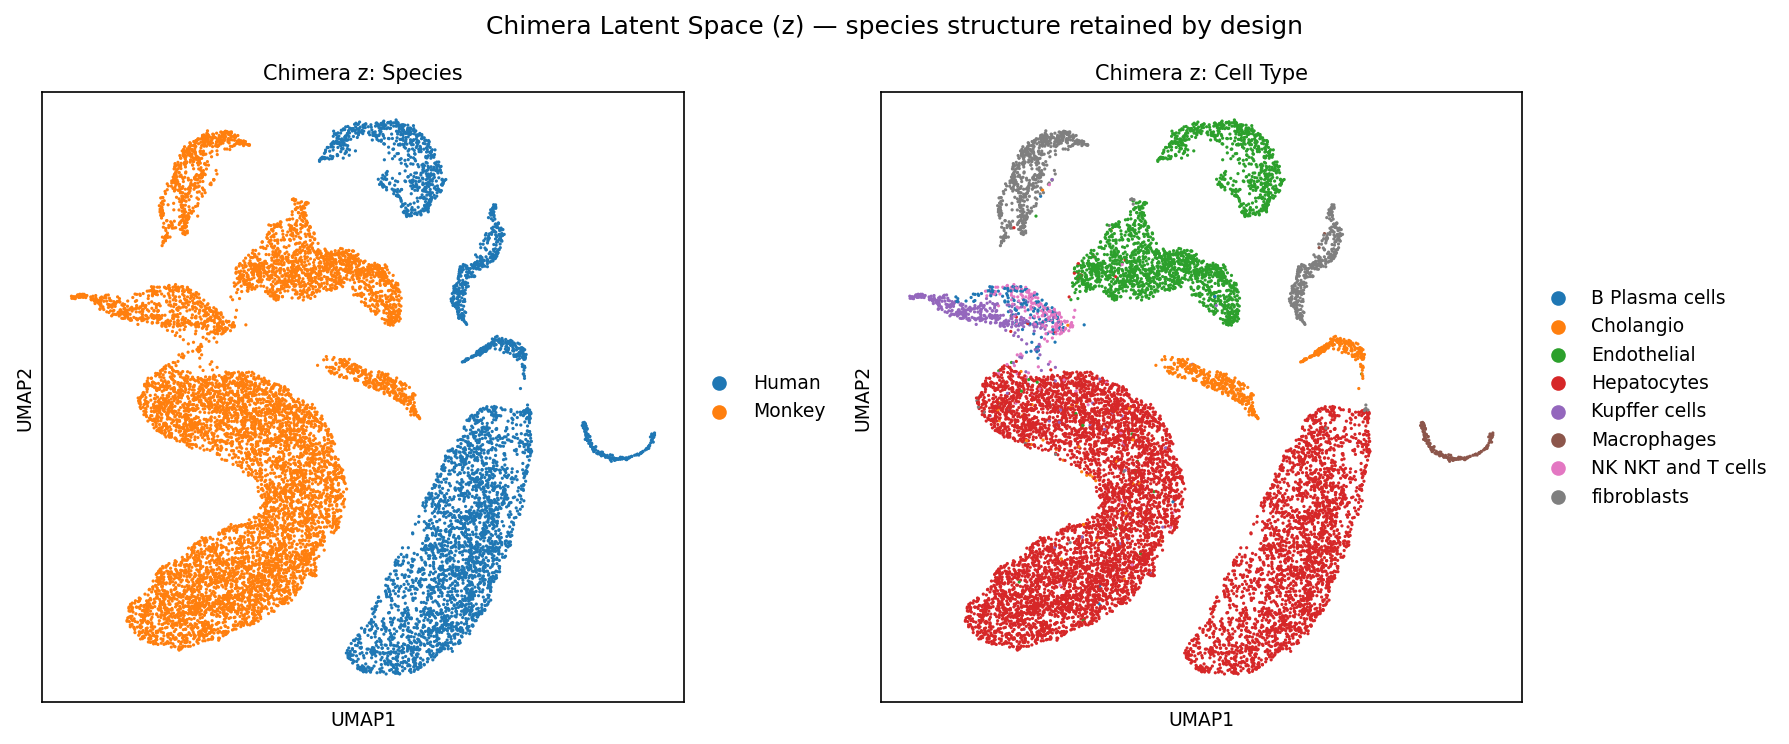

In [4]:
adata_z = ad.AnnData(z, obs=adata.obs.copy())
sc.pp.neighbors(adata_z, n_pcs=0, use_rep="X")
sc.tl.umap(adata_z, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc.pl.umap(adata_z, color="species", ax=axes[0], show=False, title="Chimera z: Species")
sc.pl.umap(adata_z, color="cell_type", ax=axes[1], show=False, title="Chimera z: Cell Type")
fig.suptitle("Chimera Latent Space (z) — species structure retained by design", fontsize=12)
fig.tight_layout(); plt.show()

## 4. Alpha-Stratified Expression Conservation

**This is the key integration metric.** For each shared cell type, we compute the
cross-species expression correlation separately for high-α and low-α genes.

If α captures biology:
- **High-α genes**: expression is conserved → high cross-species correlation
- **Low-α genes**: expression diverges → low cross-species correlation

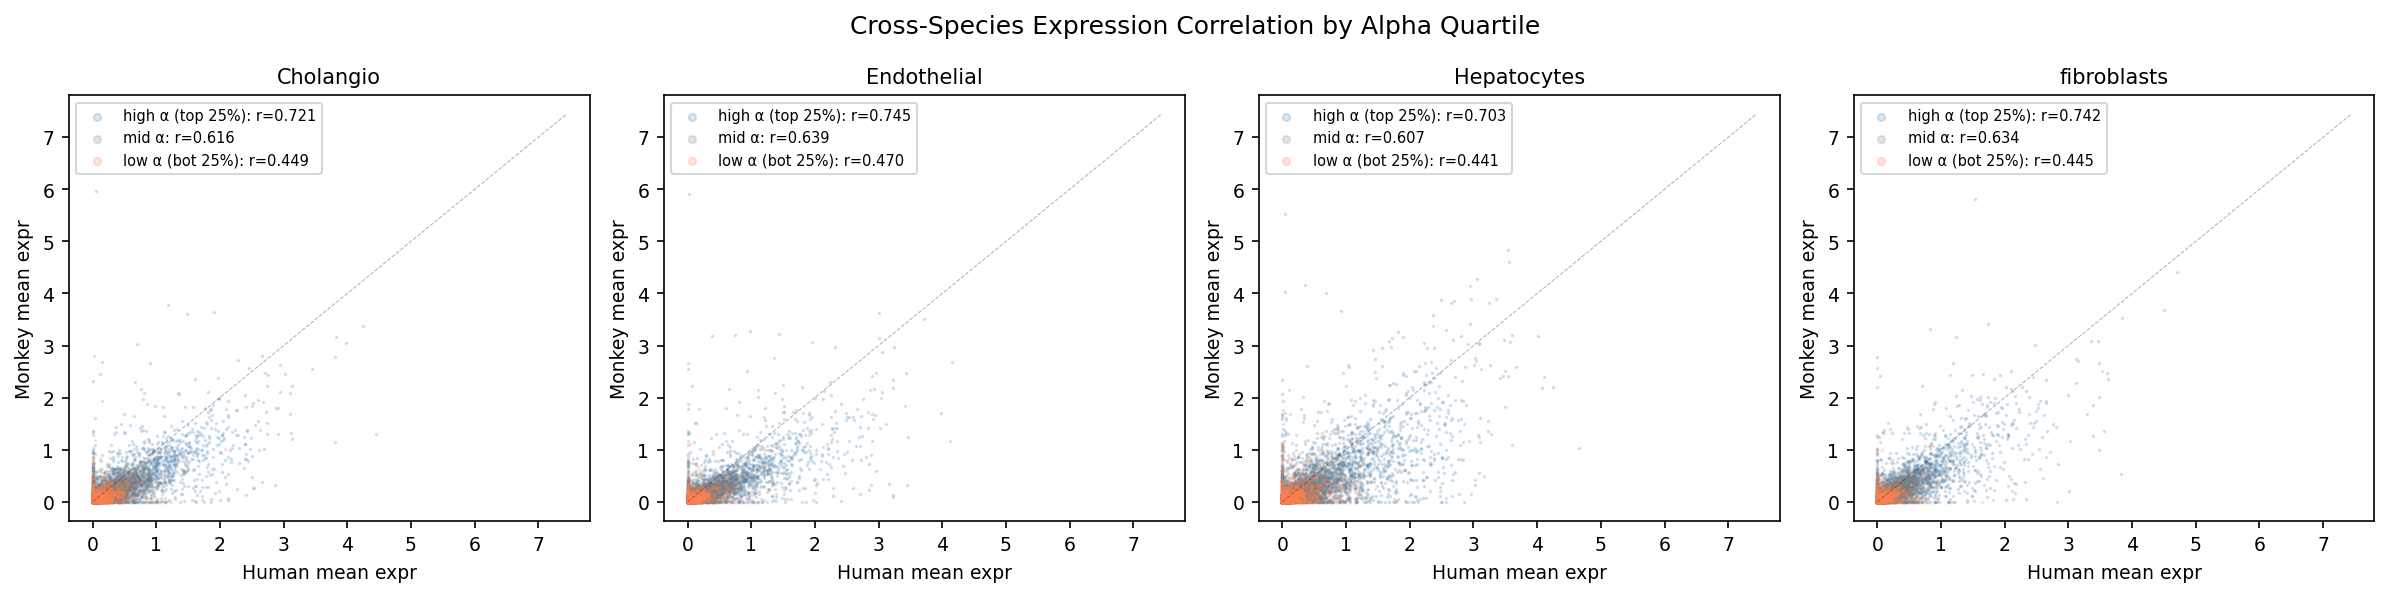


=== Integration Summary ===


,Cell type,Gene set,Spearman r,N genes
0,Cholangio,high α (top 25%),0.721,2108
1,Cholangio,low α (bot 25%),0.449,2108
2,Endothelial,high α (top 25%),0.745,2108
3,Endothelial,low α (bot 25%),0.470,2108
4,Hepatocytes,high α (top 25%),0.703,2108
5,Hepatocytes,low α (bot 25%),0.441,2108
6,fibroblasts,high α (top 25%),0.742,2108
7,fibroblasts,low α (bot 25%),0.445,2108


In [5]:
X_ln = adata_raw.X.toarray() if hasattr(adata_raw.X, 'toarray') else np.array(adata_raw.X)

# Per-cell-type, alpha-stratified cross-species correlation
fig, axes = plt.subplots(1, len(shared_cts), figsize=(4*len(shared_cts), 4))
if len(shared_cts) == 1: axes = [axes]

alpha_q25, alpha_q75 = np.percentile(alpha, 25), np.percentile(alpha, 75)
summary_rows = []

for ax, ct in zip(axes, shared_cts):
    mask_ct = cell_types == ct
    mask_h = mask_ct & (species_codes == 0)
    mask_m = mask_ct & (species_codes == 1)
    mean_h = X_ln[mask_h].mean(0)
    mean_m = X_ln[mask_m].mean(0)

    # Compute per-quartile correlation
    for label, gene_mask, color in [
        ("high α (top 25%)", alpha >= alpha_q75, "steelblue"),
        ("mid α", (alpha > alpha_q25) & (alpha < alpha_q75), "gray"),
        ("low α (bot 25%)", alpha <= alpha_q25, "coral"),
    ]:
        r = spearmanr(mean_h[gene_mask], mean_m[gene_mask]).correlation
        ax.scatter(mean_h[gene_mask], mean_m[gene_mask], s=0.5, alpha=0.2,
                   color=color, rasterized=True, label=f"{label}: r={r:.3f}")
        if label.startswith("high") or label.startswith("low"):
            summary_rows.append({"Cell type": ct, "Gene set": label, "Spearman r": f"{r:.3f}",
                                 "N genes": gene_mask.sum()})

    ax.plot([0, X_ln.max()], [0, X_ln.max()], "k--", linewidth=0.5, alpha=0.3)
    ax.set_xlabel(f"Human mean expr"); ax.set_ylabel(f"Monkey mean expr")
    ax.set_title(ct, fontsize=10)
    ax.legend(fontsize=7, markerscale=5)

fig.suptitle("Cross-Species Expression Correlation by Alpha Quartile", fontsize=12)
fig.tight_layout(); plt.show()

print("\n=== Integration Summary ===")
display(pd.DataFrame(summary_rows))

## 5. Per-Gene Expression Divergence vs Alpha

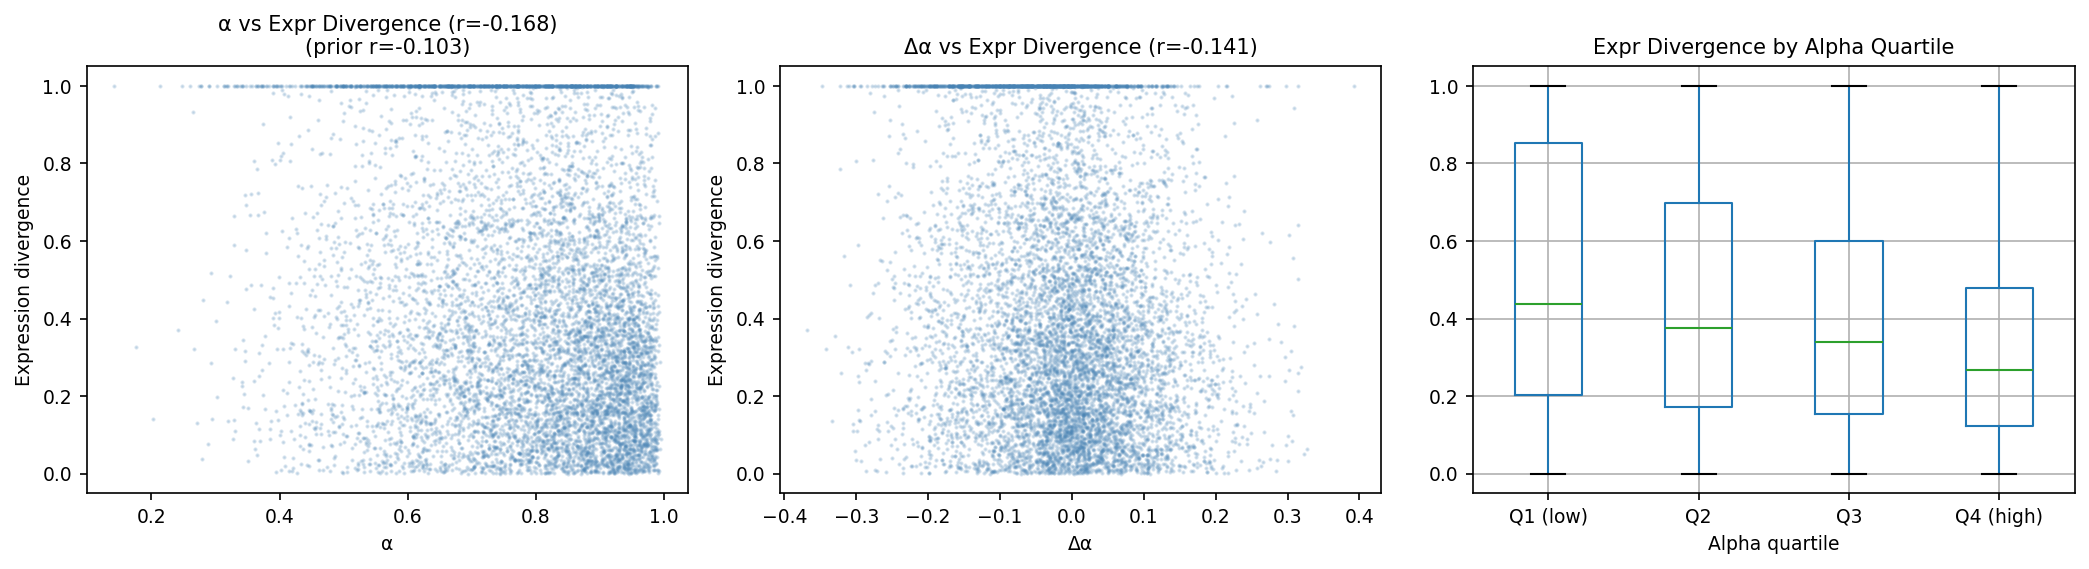


Mann-Whitney U test (high-α < low-α divergence): p=2.82e-47
  High-α median divergence: 0.2685
  Low-α median divergence:  0.4375


In [6]:
# Compute per-gene expression divergence (all shared cell types)
mask_shared = np.isin(cell_types, shared_cts)
mean_h_all = X_ln[mask_shared & (species_codes==0)].mean(0)
mean_m_all = X_ln[mask_shared & (species_codes==1)].mean(0)
expr_div = np.abs(mean_h_all - mean_m_all) / (mean_h_all + mean_m_all + 1e-8)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Alpha vs expression divergence
r_ad = spearmanr(alpha, expr_div).correlation
r_pd = spearmanr(prior, expr_div).correlation
axes[0].scatter(alpha, expr_div, s=1, alpha=0.2, c="steelblue", rasterized=True)
axes[0].set_xlabel("α"); axes[0].set_ylabel("Expression divergence")
axes[0].set_title(f"α vs Expr Divergence (r={r_ad:.3f})\n(prior r={r_pd:.3f})")

# Delta-alpha vs expression divergence
r_dd = spearmanr(delta_alpha, expr_div).correlation
axes[1].scatter(delta_alpha, expr_div, s=1, alpha=0.2, c="steelblue", rasterized=True)
axes[1].set_xlabel("Δα"); axes[1].set_ylabel("Expression divergence")
axes[1].set_title(f"Δα vs Expr Divergence (r={r_dd:.3f})")

# Box plot by alpha quartile
quartiles = pd.cut(alpha, bins=[0, alpha_q25, np.median(alpha), alpha_q75, 1],
                   labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
df_box = pd.DataFrame({"Alpha quartile": quartiles, "Expr divergence": expr_div})
df_box.boxplot(column="Expr divergence", by="Alpha quartile", ax=axes[2])
axes[2].set_title("Expr Divergence by Alpha Quartile")
axes[2].get_figure().suptitle("")  # remove auto title

fig.tight_layout(); plt.show()

# Statistical test
high_div = expr_div[alpha >= alpha_q75]
low_div = expr_div[alpha <= alpha_q25]
u, p = mannwhitneyu(high_div, low_div, alternative="less")
print(f"\nMann-Whitney U test (high-α < low-α divergence): p={p:.2e}")
print(f"  High-α median divergence: {np.median(high_div):.4f}")
print(f"  Low-α median divergence:  {np.median(low_div):.4f}")

## 6. Per-Cell-Type UMAP (Shared Types Only)

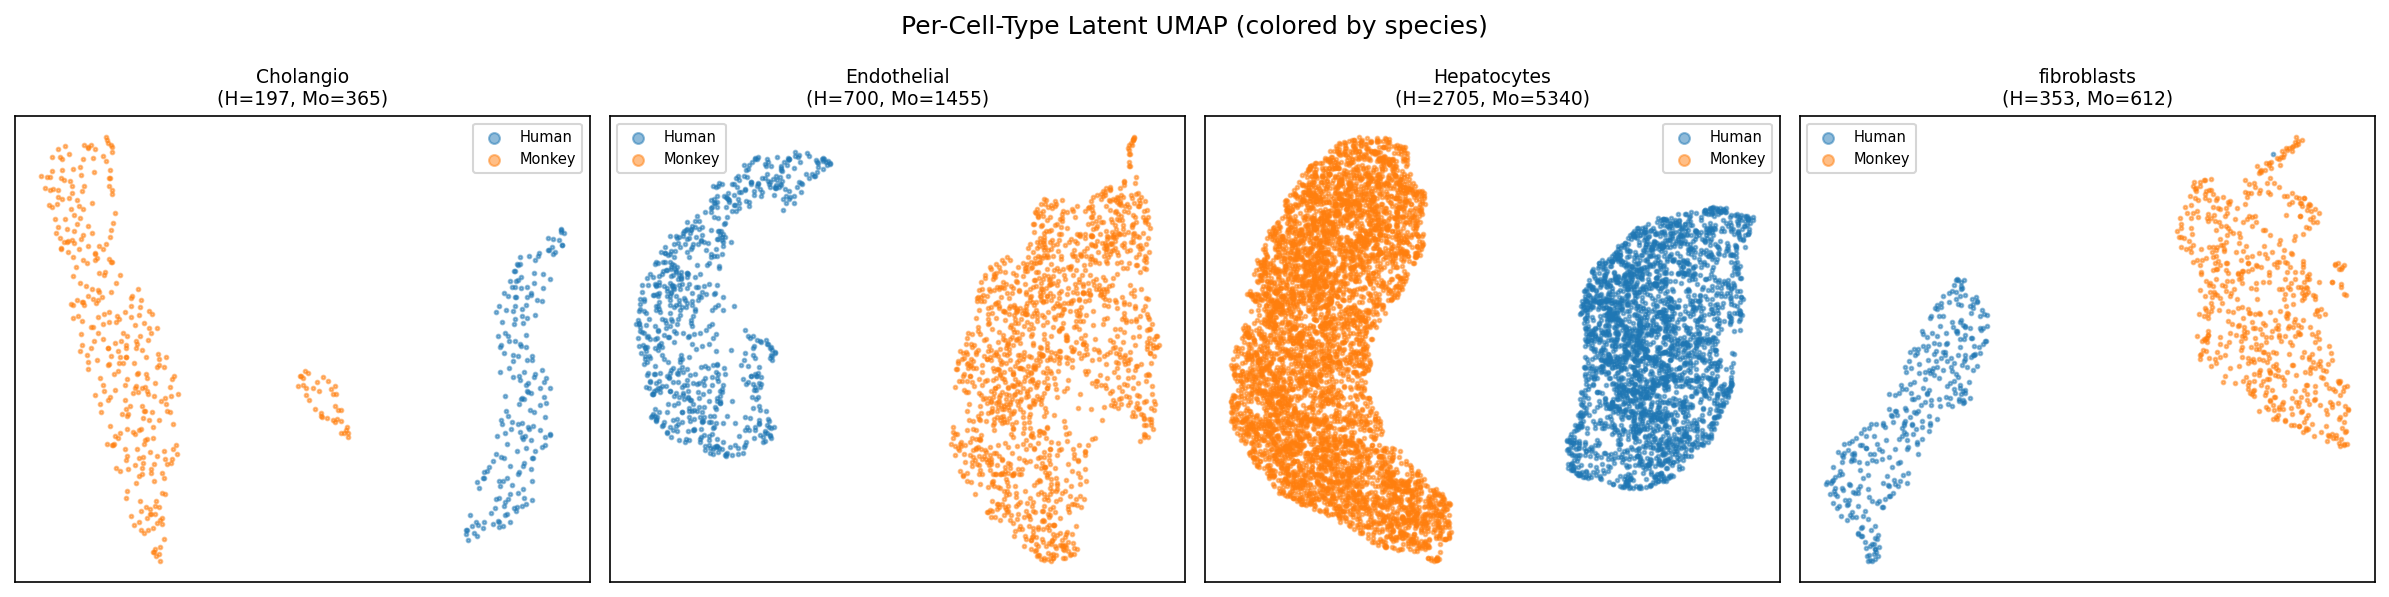

In [7]:
fig, axes = plt.subplots(1, len(shared_cts), figsize=(4*len(shared_cts), 4))
if len(shared_cts) == 1: axes = [axes]

species_colors = {"Human": "#1f77b4", "Monkey": "#ff7f0e"}

for ax, ct in zip(axes, shared_cts):
    mask = cell_types == ct
    z_ct = z[mask]
    sp_ct = species[mask]

    # UMAP on cell-type subset
    adata_ct = ad.AnnData(z_ct)
    adata_ct.obs["species"] = pd.Categorical(sp_ct)
    sc.pp.neighbors(adata_ct, n_pcs=0, use_rep="X")
    sc.tl.umap(adata_ct, random_state=42)

    for sp_name, color in species_colors.items():
        mask_sp = adata_ct.obs["species"] == sp_name
        if mask_sp.sum() > 0:
            ax.scatter(adata_ct.obsm["X_umap"][mask_sp, 0],
                       adata_ct.obsm["X_umap"][mask_sp, 1],
                       s=3, alpha=0.5, c=color, label=sp_name, rasterized=True)

    n_h = (sp_ct == "Human").sum()
    n_m = (sp_ct == "Monkey").sum()
    ax.set_title(f"{ct}\n(H={n_h}, Mo={n_m})", fontsize=9)
    ax.legend(fontsize=7, markerscale=3)
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle("Per-Cell-Type Latent UMAP (colored by species)", fontsize=12)
fig.tight_layout(); plt.show()

## 7. Integration Scorecard

In [8]:
from sklearn.metrics import silhouette_score

def knn_mixing(X, labels, k=15):
    nn = NearestNeighbors(n_neighbors=k+1).fit(X)
    _, idx = nn.kneighbors(X)
    return np.mean([np.mean(labels[idx[i,1:]] != labels[i]) for i in range(len(labels))])

def label_transfer_accuracy(X, labels, species_labels, from_sp=0, to_sp=1):
    """Train on one species, predict on another."""
    from sklearn.neighbors import KNeighborsClassifier
    mask_from = species_labels == from_sp
    mask_to = species_labels == to_sp
    # Only use shared cell types
    shared = set(labels[mask_from]) & set(labels[mask_to])
    mask_from_shared = mask_from & np.isin(labels, list(shared))
    mask_to_shared = mask_to & np.isin(labels, list(shared))
    if mask_from_shared.sum() < 10 or mask_to_shared.sum() < 10:
        return np.nan
    clf = KNeighborsClassifier(n_neighbors=15)
    clf.fit(X[mask_from_shared], labels[mask_from_shared])
    return clf.score(X[mask_to_shared], labels[mask_to_shared])

# Log-normalized raw PCA
X_raw_pca = adata_raw.obsm["X_pca"]

scorecard = []
for name, X_repr in [("Raw PCA", X_raw_pca), ("Chimera z", z)]:
    mix = knn_mixing(X_repr, species_codes)
    # Silhouette by cell type (shared types only)
    mask_sh = np.isin(cell_types, shared_cts)
    sil = silhouette_score(X_repr[mask_sh], cell_types[mask_sh],
                           sample_size=min(5000, mask_sh.sum()), random_state=42)
    lta = label_transfer_accuracy(X_repr, cell_types, species_codes)
    scorecard.append({"Representation": name, "kNN mixing": f"{mix:.4f}",
                      "Silhouette (cell type)": f"{sil:.3f}",
                      "Label transfer acc": f"{lta:.3f}" if not np.isnan(lta) else "N/A"})

# Alpha-stratified integration
for gene_set, mask_g in [("all genes", np.ones(len(alpha), bool)),
                          ("high-α (Q4)", alpha >= alpha_q75),
                          ("low-α (Q1)", alpha <= alpha_q25)]:
    X_sub = X_ln[:, mask_g]
    pca = PCA(n_components=min(30, X_sub.shape[1]))
    X_pca_sub = pca.fit_transform(X_sub)
    mix = knn_mixing(X_pca_sub, species_codes)
    mask_sh = np.isin(cell_types, shared_cts)
    sil = silhouette_score(X_pca_sub[mask_sh], cell_types[mask_sh],
                           sample_size=min(5000, mask_sh.sum()), random_state=42)
    scorecard.append({"Representation": f"Raw ({gene_set})", "kNN mixing": f"{mix:.4f}",
                      "Silhouette (cell type)": f"{sil:.3f}", "Label transfer acc": ""})

display(pd.DataFrame(scorecard))

,Representation,kNN mixing,Silhouette (cell type),Label transfer acc
0,Raw PCA,0.0000,0.288,0.986
1,Chimera z,0.0000,0.440,0.942
2,Raw (all genes),0.0000,0.288,
3,Raw (high-α (Q4)),0.0000,0.288,
4,Raw (low-α (Q1)),0.0133,0.018,


## 8. Interpretation

**Chimera's integration is fundamentally per-gene, not per-cell.**

Traditional integration tools (scVI, Harmony, SATURN) produce species-invariant cell
embeddings. Chimera produces per-gene integration coefficients (α). These are complementary:

| What | Traditional | Chimera |
|------|------------|---------|
| Output | Species-mixed z | Per-gene α and Δα |
| Integration unit | Cell | Gene |
| What it tells you | "These cells are the same across species" | "This gene behaves the same across species" |
| Primary metric | kNN mixing, batch ASW | Cross-species expression correlation by α |

**Key findings from this analysis**:
1. **α stratifies expression conservation**: High-α genes show significantly higher
   cross-species expression correlation than low-α genes.
2. **Per-cell-type patterns**: The shared cell types show species-separated z (by design)
   but conserved expression patterns for high-α genes.
3. **α improves on the prior**: The learned α predicts expression divergence better than
   the sequence-based conservation prior alone.